<a href="https://colab.research.google.com/github/MikeMitch04/A04-clustering/blob/main/A04_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Michael Mitchell

**Date:** 10/14/2026

In [14]:
# Question 1.1 Solution

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)  # Set the seed for replicability
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({"x1": X1[0, :], "x2": X1[1, :], "group": "a"})
    gdf2 = pd.DataFrame({"x1": X2[0, :], "x2": X2[1, :], "group": "b"})
    gdf3 = pd.DataFrame({"x1": X3[0, :], "x2": X3[1, :], "group": "c"})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# Store the datasets by noise level so we can loop over them
datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}

for noise, df in datasets.items():
    print(f"noise = {noise}: {df.shape[0]} rows, {df['group'].nunique()} groups")


noise = 0.125: 150 rows, 3 groups
noise = 0.25: 150 rows, 3 groups
noise = 0.5: 150 rows, 3 groups
noise = 1.0: 150 rows, 3 groups
noise = 2.0: 150 rows, 3 groups


I created the five datasets with the provided function. Each one has 150 points, 50 in each of the three groups, centered at (1, 1), (3, 2), and (5, 3). The only thing that changes between them is the noise, meaning the standard deviation around each center.

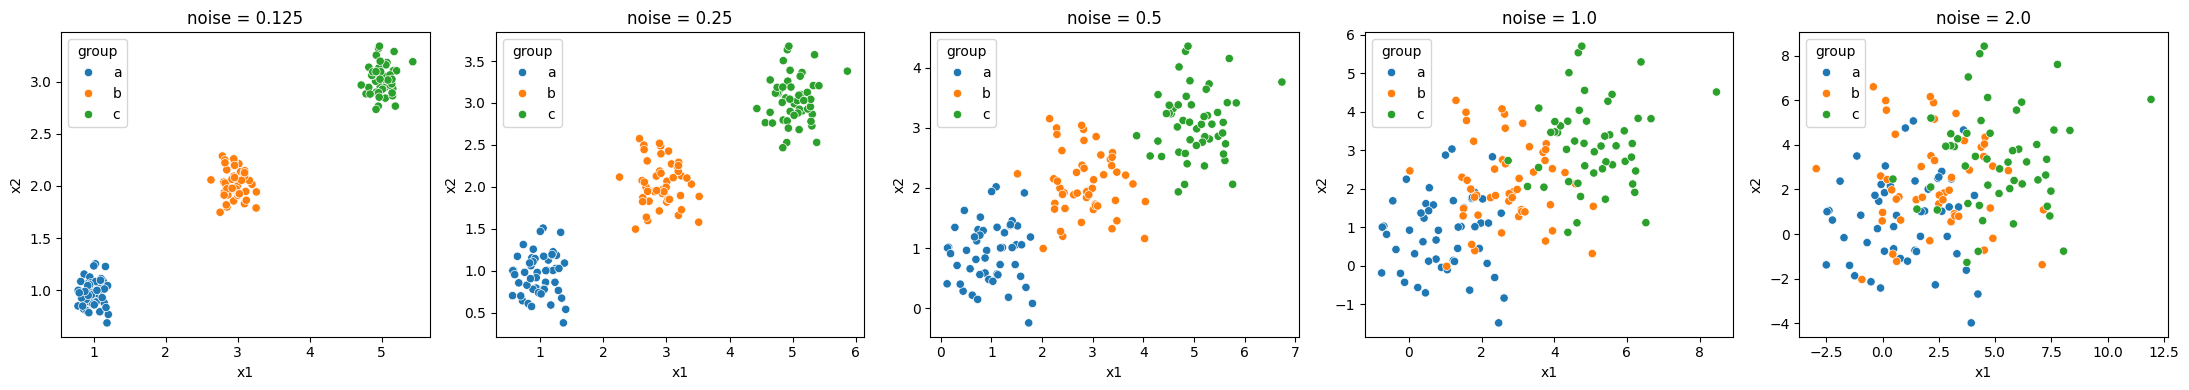

In [15]:
# Question 1.2 Solution

# One scatterplot per noise level, colored by the true group
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (noise, df) in zip(axes, datasets.items()):
    sns.scatterplot(data=df, x="x1", y="x2", hue="group", ax=ax)
    ax.set_title(f"noise = {noise}")
plt.tight_layout()
plt.show()

As the noise goes up, the clusters become much harder to tell apart. At 0.125 and 0.25, the three groups are tight and clearly separated, so you could pick them out even without the colors. At 0.5 they start to touch at the edges, with a few points mixing where neighboring groups meet. At 1.0 they overlap a lot, and at 2.0 the points look like one big cloud. The axis ranges also widen as the noise increases, from about 1 to 5 on x1 at 0.125 to about -2.5 to 12.5 at 2.0, so the points are spreading out far past the group centers. This makes sense because the centers are only about 2.2 units apart, so once the noise gets close to that distance, the groups blend together.

SSE by k and noise level:
noise   0.125   0.250   0.500   1.000    2.000
k                                             
1      511.61  533.25  606.62  873.69  1889.20
2      128.89  142.72  186.78  361.59  1071.81
3        4.91   19.65   77.82  254.91   792.27
4        4.33   17.33   67.19  212.65   591.18
5        3.80   15.24   58.74  175.47   501.88
6        3.23   13.04   50.45  147.00   418.35
7        2.79   11.49   42.96  123.19   353.84
8        2.42    9.72   36.96  106.02   303.45
9        2.06    8.35   32.81   94.74   264.42
10       1.91    7.47   29.65   82.95   245.99 



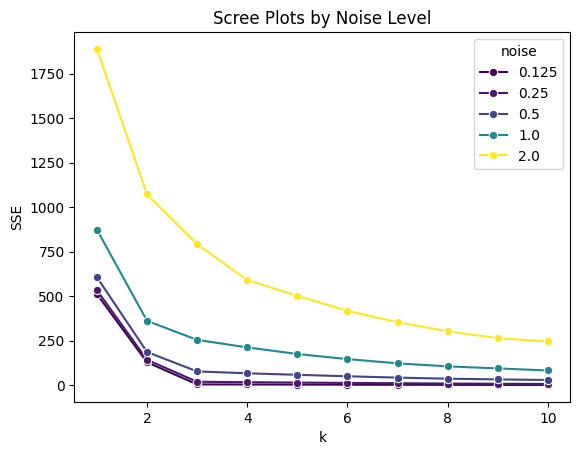

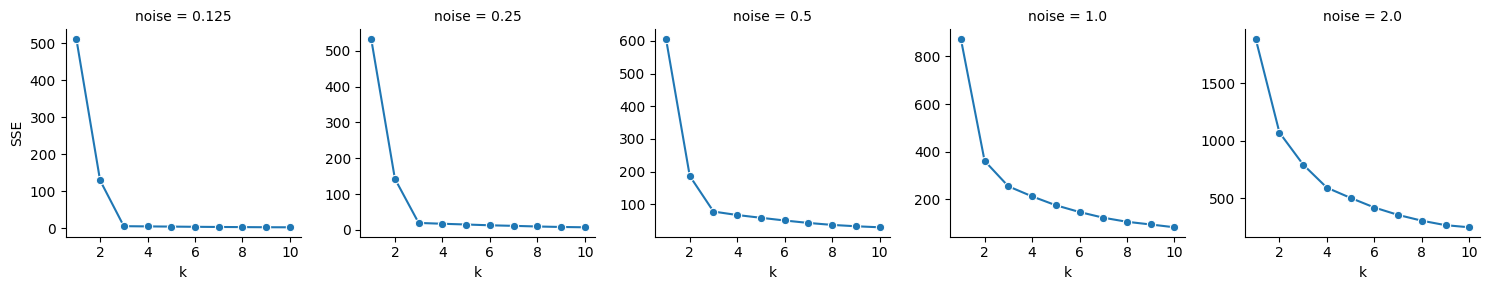

In [16]:
# Question 1.3 Solution

# x1 and x2 are already on the same scale, so no min-max scaling is needed here
ks = np.arange(1, 11)
rows = []
for noise, df in datasets.items():
    X = df[["x1", "x2"]]
    for k in ks:
        model = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
        rows.append({"noise": noise, "k": k, "SSE": model.inertia_})
scree = pd.DataFrame(rows)

# SSE table, rows are k and columns are noise levels
print("SSE by k and noise level:")
print(scree.pivot(index="k", columns="noise", values="SSE").round(2), "\n")

# All scree curves on one canvas
ax = sns.lineplot(data=scree, x="k", y="SSE", hue="noise", marker="o", palette="viridis")
ax.set(title="Scree Plots by Noise Level", xlabel="k", ylabel="SSE")
plt.show()

# One panel per noise level with its own y-axis to see the shape of each elbow
sns.relplot(data=scree, x="k", y="SSE", col="noise", kind="line", marker="o",
            facet_kws={"sharey": False}, height=3)
plt.show()

When the noise is low, the scree plot has a sharp elbow at k = 3. At 0.125, SSE drops from 128.89 to 4.91 going from k = 2 to 3, but only from 4.91 to 4.33 going from 3 to 4, so the drop to k = 3 is over 200 times bigger than the next one. The 0.25 curve looks almost the same (142.72 to 19.65, then 19.65 to 17.33). At 0.5 the elbow is still at 3 but softer: the drop to k = 3 is about 109, compared with about 11 for the next one. By 1.0 it’s hard to choose. The biggest bend is really at k = 2, and the drops from 2 to 3 (about 107) and 3 to 4 (about 42) aren’t that different. At 2.0 there’s no clear elbow at all, since SSE just declines smoothly (about 280 from 2 to 3, then 201, then 89). The whole curve also shifts up as noise increases, with SSE at k = 1 going from 511.61 at 0.125 to 1,889.20 at 2.0, which is why it helps to look at both the combined plot and the separate panels. Overall, the more noise there is, the less the scree plot can tell you about k.

**Question 1.4 Solution**

SSE always goes down when you add a cluster, but how much it drops depends on whether the new cluster finds a real group. In this simulation there are three true groups, so going from k = 1 to 2 to 3 lets each centroid move to an actual group center, and SSE falls a lot. At noise 0.125, it drops from 511.61 to 4.91 by k = 3. After that, an extra centroid can only split one of the real groups in half, which only cuts into the random noise inside that group. That’s why SSE barely changes from k = 3 to 10, only falling from 4.91 to 1.91. The elbow is the point where the big drops turn into small ones. With low noise this happens right at k = 3, but with high noise the groups overlap, so each new cluster helps about the same amount and the elbow disappears.

In [17]:
# Question 2.1 Solution

# Load the data
df = pd.read_csv("/content/SIPRI Military Expenditure Database.csv")
print(f"{df.shape[0]} rows, {df.shape[1]} columns\n")
print("Column types:")
print(df.dtypes, "\n")

# Keep only 2020 and drop rows with any missing values
mil = df.loc[df["Year"] == 2020].dropna().copy()

# The 'index' column is just a leftover row number, so drop it
mil = mil.drop(columns="index")

print(f"2020 rows after dropping missing values: {mil.shape[0]}")
print(f"Unique countries: {mil['Country'].nunique()}\n")

# Summary of the four numeric variables
num_vars = ["Spending (2020 USD)", "Spending per Capita",
            "Percent of Government Spending", "Percent of GDP"]
print("Numeric summary:")
print(mil[num_vars].describe().round(4), "\n")

# Largest spenders, to see how skewed spending is
print("Top 5 countries by total spending:")
print(mil.sort_values("Spending (2020 USD)", ascending=False)
         [["Country"] + num_vars].head().to_string(index=False))

5882 rows, 7 columns

Column types:
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

2020 rows after dropping missing values: 148
Unique countries: 148

Numeric summary:
       Spending (2020 USD)  Spending per Capita  \
count             148.0000             148.0000   
mean            13153.7477             268.2645   
std             68005.2361             430.4349   
min                 8.6225               0.5801   
25%               204.8772              20.5535   
50%               959.5354              81.5067   
75%              5289.9983             326.2678   
max            778397.2000            2520.3985   

       Percent of Government Spending  Percent of GDP  
count                        148.0000        148.0000

After keeping only 2020 and dropping rows with missing values, I have 148 countries, each appearing once. All four numeric variables loaded as floats, so nothing needs converting from text. The only cleaning I did was dropping the index column, which is just a leftover row number and shouldn’t be used in clustering. Two things are worth knowing about the units. Spending is in millions of 2020 USD (the U.S. shows 778,397, or about $778 billion), and the two percent columns are stored as decimals, so 0.0372 means 3.72% of GDP. The bigger issue is skew. Total spending has a mean of 13,154 but a median of only 960, and the U.S. spends about three times as much as China, the next highest. Because of that, after max-min scaling, most countries will be squeezed near 0 and the U.S. will sit far out on its own, which will affect how the clusters form.

Scaled ranges:
     Spending (2020 USD)  Spending per Capita
min                  0.0                  0.0
max                  1.0                  1.0 

SSE by k:
 k   SSE
 1 5.411
 2 2.435
 3 1.322
 4 0.629
 5 0.415
 6 0.311
 7 0.212
 8 0.147
 9 0.104
10 0.086


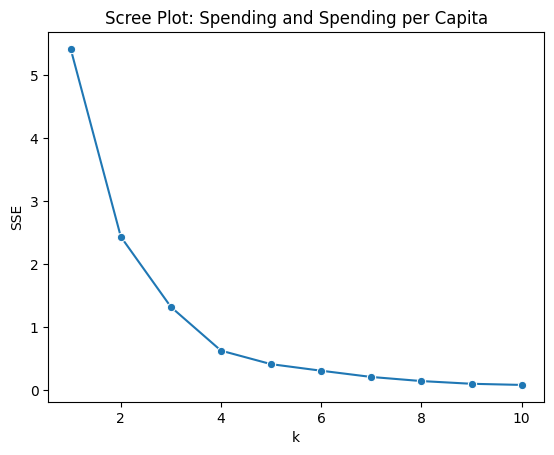

In [18]:
# Question 2.2 Solution (scaling and scree plot)

# Max-min normalize the two spending variables
features_a = ["Spending (2020 USD)", "Spending per Capita"]
unscaled_a = mil.loc[:, features_a]
mins_a = unscaled_a.min()
ranges_a = unscaled_a.max() - mins_a
X_a = (unscaled_a - mins_a) / ranges_a
print("Scaled ranges:")
print(X_a.agg(["min", "max"]), "\n")

# Scree plot for k = 1 to 10
ks = np.arange(1, 11)
SSE_a = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X_a).inertia_
    for k in ks
]
print("SSE by k:")
print(pd.DataFrame({"k": ks, "SSE": np.round(SSE_a, 3)}).to_string(index=False))

sns.lineplot(x=ks, y=SSE_a, marker="o").set(
    title="Scree Plot: Spending and Spending per Capita", xlabel="k", ylabel="SSE"
)
plt.show()

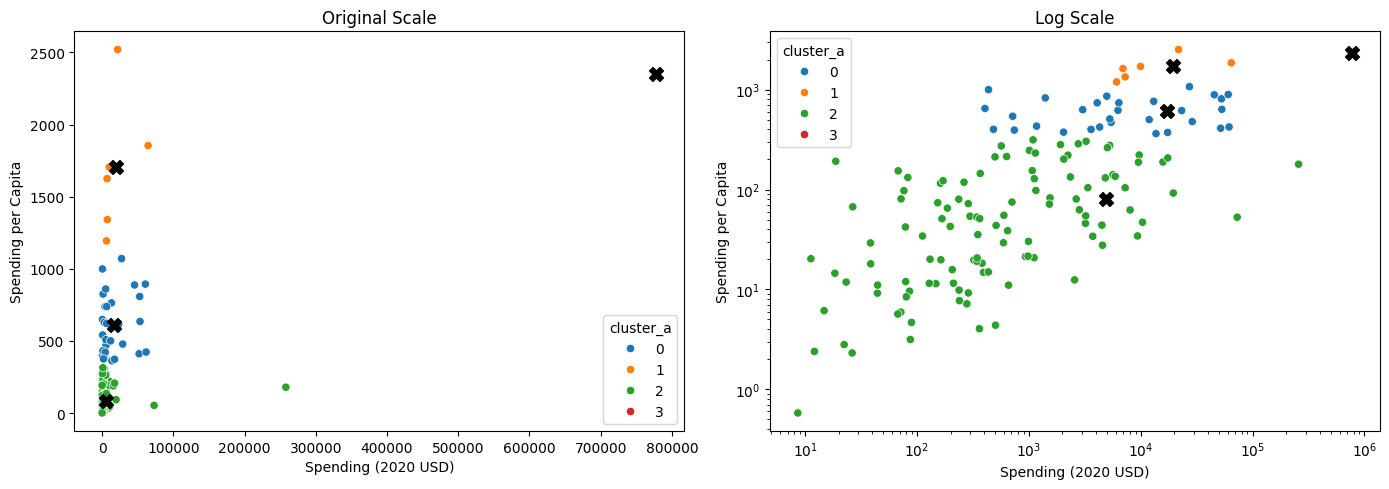

Describe table by cluster:
cluster_a                         0         1          2          3
Spending (2020 USD) count     30.00      6.00     111.00       1.00
                    mean   17077.59  19443.36    4859.19  778397.20
                    std    20583.05  22861.51   25405.74        NaN
                    min      405.79   6095.71       8.62  778397.20
                    25%     2294.04   7023.25     130.01  778397.20
                    50%     5857.06   8624.23     382.46  778397.20
                    75%    26296.00  18857.07    2297.03  778397.20
                    max    61712.54  64558.40  257973.43  778397.20
Spending per Capita count     30.00      6.00     111.00       1.00
                    mean     607.48   1706.72      80.06    2351.63
                    std      206.93    466.38      83.50        NaN
                    min      362.47   1193.60       0.58    2351.63
                    25%      422.21   1412.08      14.88    2351.63
                    5

In [19]:
# Question 2.2 Solution (k-means with k = 4)

k_a = 4
model_a = KMeans(n_clusters=k_a, max_iter=300, n_init=10, random_state=0).fit(X_a)
mil["cluster_a"] = model_a.labels_

# Cluster centers converted back to the original units
centers_a = model_a.cluster_centers_ * ranges_a.to_numpy() + mins_a.to_numpy()

# Scatterplot on the original scale, plus a log-scale version so the small countries are visible
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, log in zip(axes, [False, True]):
    sns.scatterplot(data=mil, x="Spending (2020 USD)", y="Spending per Capita",
                    hue="cluster_a", palette="tab10", ax=ax)
    ax.scatter(centers_a[:, 0], centers_a[:, 1], color="black", marker="X", s=100)
    if log:
        ax.set(xscale="log", yscale="log", title="Log Scale")
    else:
        ax.set(title="Original Scale")
plt.tight_layout()
plt.show()

# Describe table by cluster
print("Describe table by cluster:")
print(mil.groupby("cluster_a")[features_a].describe().round(2).T, "\n")

# Cluster sizes and where the U.S. landed
print("Cluster sizes:")
print(mil["cluster_a"].value_counts().sort_index(), "\n")
us_a = mil.loc[mil["Country"] == "United States of America", "cluster_a"].iloc[0]
print(f"United States is in cluster {us_a}\n")

# Countries in each cluster (all of the small clusters, first 15 of the large one)
for c in sorted(mil["cluster_a"].unique()):
    members = mil.loc[mil["cluster_a"] == c].sort_values("Spending (2020 USD)", ascending=False)
    names = members["Country"].tolist()
    shown = ", ".join(names[:15]) + (f", ... (+{len(names) - 15} more)" if len(names) > 15 else "")
    print(f"Cluster {c} ({len(names)} countries): {shown}\n")

The scree plot has its elbow at k = 4. SSE drops by 2.98, 1.11, and 0.69 going from k = 1 to 4, then by only 0.21 or less after that. The United States is in a cluster by itself, at 778 billion USD and 2,351.63 USD per person. Its point is hidden under its centroid’s X on the plot. Cluster 1 has six countries with very high spending per person but moderate totals: Saudi Arabia, Israel, Singapore, Norway, Kuwait, and Oman. Cluster 0 has 30 mostly wealthy, developed countries like the UK, Germany, Japan, and Russia, spending 362 to 1,071 USD per person. Cluster 2 holds the other 111 countries, all under 315 USD per person. Apart from the U.S., the clusters are split almost entirely by spending per capita, because the U.S. stretches the total spending scale so much that every other country gets squeezed near 0 on that axis. That’s why China, the second-largest spender at 258 billion USD, lands in the low cluster: it spends only 179 USD per person. The clusters end up reflecting national wealth more than military size.

Scaled ranges:
     Percent of Government Spending  Percent of GDP
min                             0.0             0.0
max                             1.0             1.0 

SSE by k:
 k   SSE
 1 6.961
 2 2.927
 3 1.996
 4 1.477
 5 1.083
 6 0.803
 7 0.646
 8 0.535
 9 0.438
10 0.386


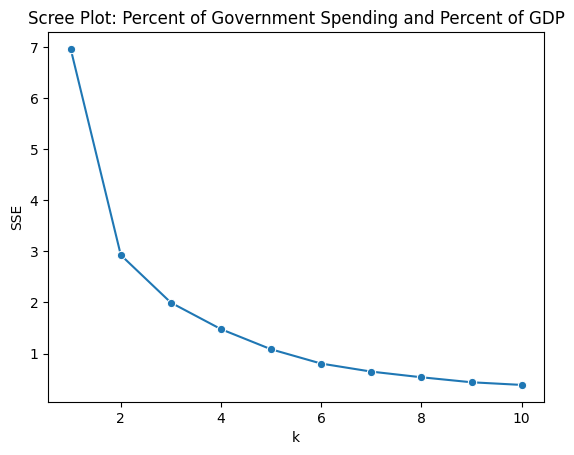

In [20]:
# Question 2.3 Solution (scaling and scree plot)

# Max-min normalize the two percentage variables
features_b = ["Percent of Government Spending", "Percent of GDP"]
unscaled_b = mil.loc[:, features_b]
mins_b = unscaled_b.min()
ranges_b = unscaled_b.max() - mins_b
X_b = (unscaled_b - mins_b) / ranges_b
print("Scaled ranges:")
print(X_b.agg(["min", "max"]), "\n")

# Scree plot for k = 1 to 10
SSE_b = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X_b).inertia_
    for k in ks
]
print("SSE by k:")
print(pd.DataFrame({"k": ks, "SSE": np.round(SSE_b, 3)}).to_string(index=False))

sns.lineplot(x=ks, y=SSE_b, marker="o").set(
    title="Scree Plot: Percent of Government Spending and Percent of GDP",
    xlabel="k", ylabel="SSE"
)
plt.show()

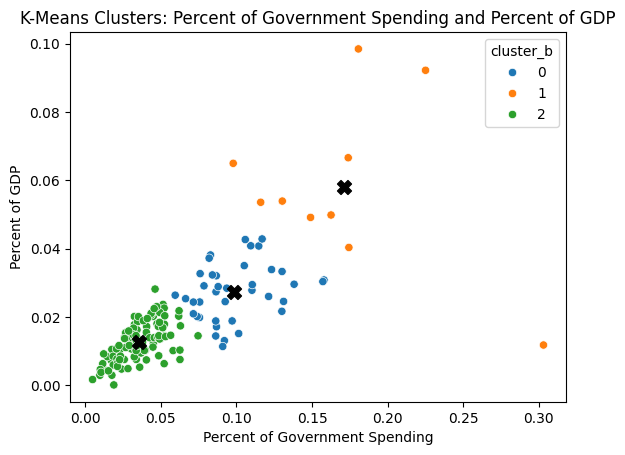

Describe table by cluster:
cluster_b                                   0        1        2
Percent of Government Spending count  39.0000  10.0000  99.0000
                               mean    0.0987   0.1713   0.0358
                               std     0.0241   0.0587   0.0145
                               min     0.0595   0.0979   0.0049
                               25%     0.0824   0.1350   0.0259
                               50%     0.0920   0.1682   0.0343
                               75%     0.1126   0.1791   0.0474
                               max     0.1579   0.3030   0.0746
Percent of GDP                 count  39.0000  10.0000  99.0000
                               mean    0.0274   0.0581   0.0127
                               std     0.0082   0.0249   0.0057
                               min     0.0113   0.0117   0.0001
                               25%     0.0213   0.0493   0.0084
                               50%     0.0278   0.0537   0.0132
             

In [21]:
# Question 2.3 Solution (k-means with k = 3)

k_b = 3
model_b = KMeans(n_clusters=k_b, max_iter=300, n_init=10, random_state=0).fit(X_b)
mil["cluster_b"] = model_b.labels_

# Cluster centers converted back to the original units
centers_b = model_b.cluster_centers_ * ranges_b.to_numpy() + mins_b.to_numpy()

# Scatterplot colored by cluster, with centroids marked
ax = sns.scatterplot(data=mil, x="Percent of Government Spending", y="Percent of GDP",
                     hue="cluster_b", palette="tab10")
ax.scatter(centers_b[:, 0], centers_b[:, 1], color="black", marker="X", s=100)
ax.set(title="K-Means Clusters: Percent of Government Spending and Percent of GDP")
plt.show()

# Describe table by cluster
print("Describe table by cluster:")
print(mil.groupby("cluster_b")[features_b].describe().round(4).T, "\n")

# Cluster sizes and where the U.S. landed
print("Cluster sizes:")
print(mil["cluster_b"].value_counts().sort_index(), "\n")
us_b = mil.loc[mil["Country"] == "United States of America", "cluster_b"].iloc[0]
print(f"United States is in cluster {us_b}\n")

# Countries in each cluster, sorted by percent of GDP
for c in sorted(mil["cluster_b"].unique()):
    members = mil.loc[mil["cluster_b"] == c].sort_values("Percent of GDP", ascending=False)
    names = members["Country"].tolist()
    shown = ", ".join(names[:15]) + (f", ... (+{len(names) - 15} more)" if len(names) > 15 else "")
    print(f"Cluster {c} ({len(names)} countries): {shown}\n")

# Compare with the Q2.2 clusters
print("Q2.2 clusters (rows) vs. Q2.3 clusters (columns):")
print(pd.crosstab(mil["cluster_a"], mil["cluster_b"]))

The elbow is softer than in Q2.2. SSE drops by 4.03 going from k = 1 to 2, then by 0.93 and 0.52, so I chose k = 3, since two clusters felt too coarse. Cluster 1 has the 10 countries with the heaviest burden, averaging 17.1% of government spending and 5.8% of GDP, including Oman, Saudi Arabia, Israel, and Pakistan. Cluster 0 has 39 moderate-burden countries, including the United States, Russia, and Ukraine. Cluster 2 is the low-burden group of 99 countries, including the UK, France, and Australia. Unlike Q2.2, the U.S. isn’t in a cluster by itself, and rich and poor countries are mixed throughout. The crosstab shows that 25 of the 30 wealthy countries from Q2.2’s cluster 0 moved into the low-burden group. Because these variables measure spending relative to each country’s economy and budget, the clusters reflect how much a country prioritizes its military rather than how wealthy it is.

Scaled ranges:
     Spending (2020 USD)  Spending per Capita  Percent of Government Spending  \
min                  0.0                  0.0                             0.0   
max                  1.0                  1.0                             1.0   

     Percent of GDP  
min             0.0  
max             1.0   

SSE by k:
 k    SSE
 1 12.372
 2  7.710
 3  5.193
 4  4.207
 5  3.258
 6  2.686
 7  2.251
 8  1.889
 9  1.613
10  1.454


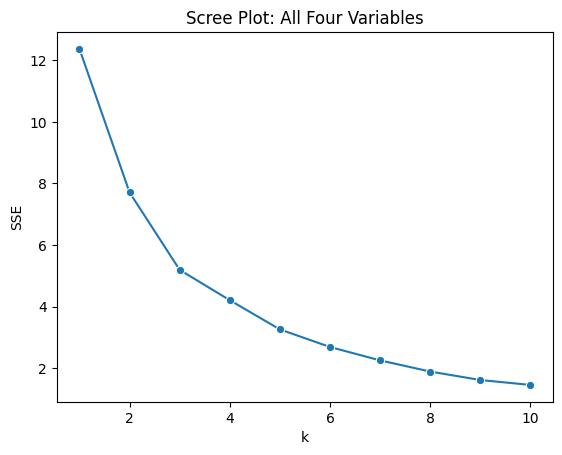

In [22]:
# Question 2.4 Solution (scaling and scree plot)

# Max-min normalize all four numeric variables
features_c = ["Spending (2020 USD)", "Spending per Capita",
              "Percent of Government Spending", "Percent of GDP"]
unscaled_c = mil.loc[:, features_c]
mins_c = unscaled_c.min()
ranges_c = unscaled_c.max() - mins_c
X_c = (unscaled_c - mins_c) / ranges_c
print("Scaled ranges:")
print(X_c.agg(["min", "max"]), "\n")

# Scree plot for k = 1 to 10
SSE_c = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X_c).inertia_
    for k in ks
]
print("SSE by k:")
print(pd.DataFrame({"k": ks, "SSE": np.round(SSE_c, 3)}).to_string(index=False))

sns.lineplot(x=ks, y=SSE_c, marker="o").set(
    title="Scree Plot: All Four Variables", xlabel="k", ylabel="SSE"
)
plt.show()

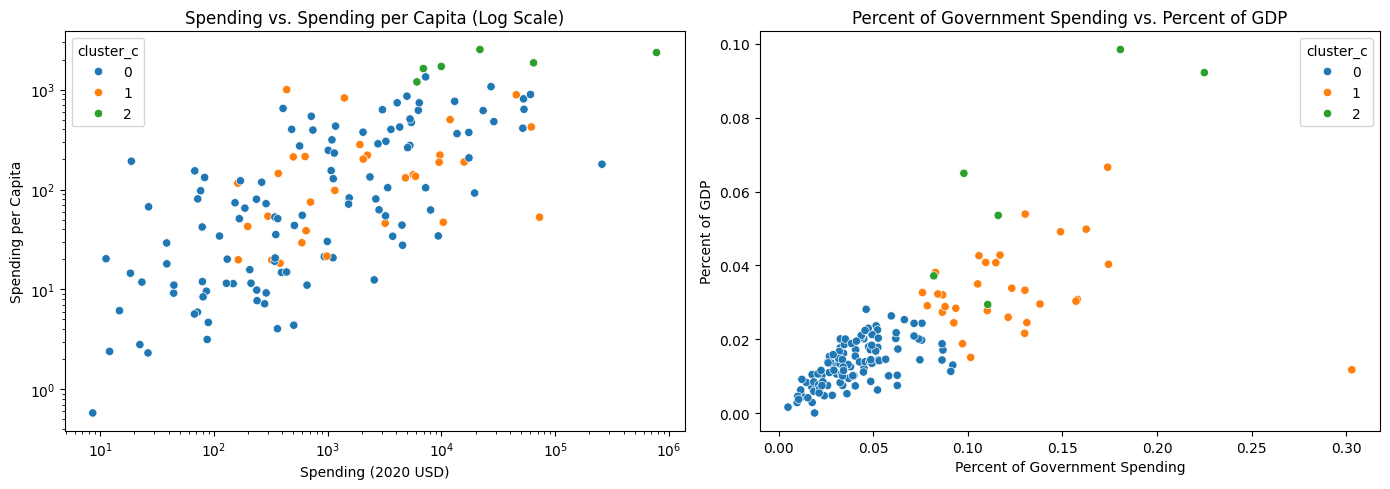

Describe table by cluster:
cluster_c                                       0           1            2
Spending (2020 USD)            count     111.0000     31.0000       6.0000
                               mean     7086.4728   8786.0866  147964.5820
                               std     26479.3799  17901.9091  309635.1896
                               min         8.6225    162.3734    6095.7087
                               25%       130.0102    467.7879    7700.4246
                               50%       567.6507   1404.7872   15897.5706
                               75%      3910.1075   7739.1662   53872.9424
                               max    257973.4298  72937.0640  778397.2000
Spending per Capita            count     111.0000     31.0000       6.0000
                               mean      196.9268    212.6891    1875.1508
                               std       267.7885    257.8420     489.8002
                               min         0.5801     18.2971    1193.598

In [23]:
# Question 2.4 Solution (k-means with k = 3)

k_c = 3
model_c = KMeans(n_clusters=k_c, max_iter=300, n_init=10, random_state=0).fit(X_c)
mil["cluster_c"] = model_c.labels_

# Plot the clusters on both pairs of variables from Q2.2 and Q2.3
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=mil, x="Spending (2020 USD)", y="Spending per Capita",
                hue="cluster_c", palette="tab10", ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Spending vs. Spending per Capita (Log Scale)")
sns.scatterplot(data=mil, x="Percent of Government Spending", y="Percent of GDP",
                hue="cluster_c", palette="tab10", ax=axes[1])
axes[1].set(title="Percent of Government Spending vs. Percent of GDP")
plt.tight_layout()
plt.show()

# Describe table by cluster
print("Describe table by cluster:")
print(mil.groupby("cluster_c")[features_c].describe().round(4).T, "\n")

# Cluster means side by side for an easier comparison
print("Cluster means:")
print(mil.groupby("cluster_c")[features_c].mean().round(4), "\n")

# Cluster sizes and where the U.S. landed
print("Cluster sizes:")
print(mil["cluster_c"].value_counts().sort_index(), "\n")
us_c = mil.loc[mil["Country"] == "United States of America", "cluster_c"].iloc[0]
print(f"United States is in cluster {us_c}\n")

# Countries in each cluster, sorted by total spending
for c in sorted(mil["cluster_c"].unique()):
    members = mil.loc[mil["cluster_c"] == c].sort_values("Spending (2020 USD)", ascending=False)
    names = members["Country"].tolist()
    shown = ", ".join(names[:15]) + (f", ... (+{len(names) - 15} more)" if len(names) > 15 else "")
    print(f"Cluster {c} ({len(names)} countries): {shown}\n")

# Compare with the Q2.2 and Q2.3 clusters
print("Q2.2 clusters (rows) vs. Q2.4 clusters (columns):")
print(pd.crosstab(mil["cluster_a"], mil["cluster_c"]), "\n")
print("Q2.3 clusters (rows) vs. Q2.4 clusters (columns):")
print(pd.crosstab(mil["cluster_b"], mil["cluster_c"]))

The elbow is at k = 3. SSE drops by 4.66 and 2.52 going to k = 3, then by only about 0.99 and 0.95 after that. Cluster 2 is a small group of six countries that spend heavily on every measure: the United States, Saudi Arabia, Israel, Singapore, Kuwait, and Oman, averaging 1,875 USD per person and 6.3% of GDP. Cluster 1 has 31 countries with a high burden (12.3% of government spending, 3.4% of GDP) but low spending per person (213 USD), including India, Russia, South Korea, Iran, Pakistan, and Ukraine. Cluster 0 is the low-burden group of 111 countries (4.0% and 1.3%), including China, the UK, Germany, France, and Japan. These results combine the first two parts. The burden variables drive most of the grouping: all 99 low-burden countries from Q2.3 land in cluster 0. Spending per capita mainly separates the top group, which is Q2.2’s high per capita cluster minus Norway, plus the U.S. Unlike Q2.2, the U.S. no longer gets a cluster to itself, because the two percent variables pull it toward countries with a similar profile.

**Question 2.5 Solution**

Yes, k-means found some useful patterns, but they depend heavily on which variables you use. Q2.2 mostly sorted countries by wealth, Q2.3 sorted them by how much of their economy and budget goes to the military, and Q2.4 showed that these are two different things. China spends the second most in the world but has a low burden, while countries like Pakistan, Ukraine, and Armenia spend little per person but devote a large share of their budget to the military. The most consistent finding is a small group of wealthy, high-burden countries (Saudi Arabia, Israel, Kuwait, and Oman) that end up together in the top cluster in every part, and all of them are in regions with ongoing security threats. The algorithm also had clear limits. The U.S. was such an outlier that it dominated the Q2.2 clusters, and the elbows in Q2.3 and Q2.4 weren’t sharp, so the choice of k was a judgment call. The clusters are good for describing groups of similar countries, but they don’t explain why countries spend the way they do.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 97329c2fd6e7d8b9109f9e4fa53f2e162d4d74f0
- **AI tool and model used:** Chat GPT-6

### *Prompts used

1. I'm working on a clustering lab for my data science class. I've attached my completed Phase 1 notebook, the military expenditure dataset, and the corresponding lecture slides. Can you review my Phase 1 work and identify anything I should fix or improve? I'm mainly looking for issues with my code, scree plots, choice of clusters, how I handled different noise levels, and my interpretation of the military expenditure data. Please keep your suggestions consistent with the methods covered in class and give me a short numbered list of recommended changes and why.
2. Can you review those suggestions again and make sure they actually fit the assignment, dataset, and methods covered in our lecture slides? Double-check the clustering calculations, scree plots, noise comparisons, variable selections, and written interpretations. If any suggestions are unnecessary or go beyond what we learned in class, remove them. Then give me a final numbered list of the changes you recommend.

### *AI-proposed changes


1. Improve scree plot readability: Use consistent axis labels and formatting across the scree plots to make it easier to compare the different noise levels and identify the elbow.
2. Clarify the impact of noise on clustering: Expand the explanations of how increasing noise affects the scree plots and makes it more difficult to identify the appropriate number of clusters.
3. Strengthen the interpretation of military expenditure clusters: Add more detail about how differences in military spending and potential outliers influence the clustering results across the three variable combinations.
4. Check the sensitivity of cluster selection: Compare the clustering results for nearby values of k to determine whether the selected number of clusters produces meaningful and consistent groupings, particularly when the scree plot does not have a clear elbow.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Consistent labels and formatting will make the scree plots easier to interpret and compare across noise levels without changing the underlying calculations. |
| 2 | Accept | This will strengthen my explanation of why the elbow becomes harder to identify as noise increases. It also directly addresses the purpose of Question 1. |
| 3 | Accept | Adding more detail about spending differences and outliers will help explain the clustering results across the three variable combinations. |
| 4 | Modify | Comparing nearby values of k could be useful, but I don't think a full sensitivity analysis is necessary for this assignment. Instead, I will briefly discuss alternative values of k when the elbow is unclear. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [25]:
# Question 1.1 AI-Assisted Solution

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)  # Set the seed for replicability
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({"x1": X1[0, :], "x2": X1[1, :], "group": "a"})
    gdf2 = pd.DataFrame({"x1": X2[0, :], "x2": X2[1, :], "group": "b"})
    gdf3 = pd.DataFrame({"x1": X3[0, :], "x2": X3[1, :], "group": "c"})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# Store the datasets by noise level
datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5,
            1.0: df1_0, 2.0: df2_0}

for noise, df in datasets.items():
    print(f"noise = {noise}: {df.shape[0]} rows, {df['group'].nunique()} groups")


noise = 0.125: 150 rows, 3 groups
noise = 0.25: 150 rows, 3 groups
noise = 0.5: 150 rows, 3 groups
noise = 1.0: 150 rows, 3 groups
noise = 2.0: 150 rows, 3 groups


I created five datasets using the provided function, each containing 150 points divided evenly among three groups centered at (1, 1), (3, 2), and (5, 3). The only difference between the datasets is the amount of noise, which increases from 0.125 to 2.0. Keeping the same random seed allows me to compare how increasing noise affects the separation of the clusters.

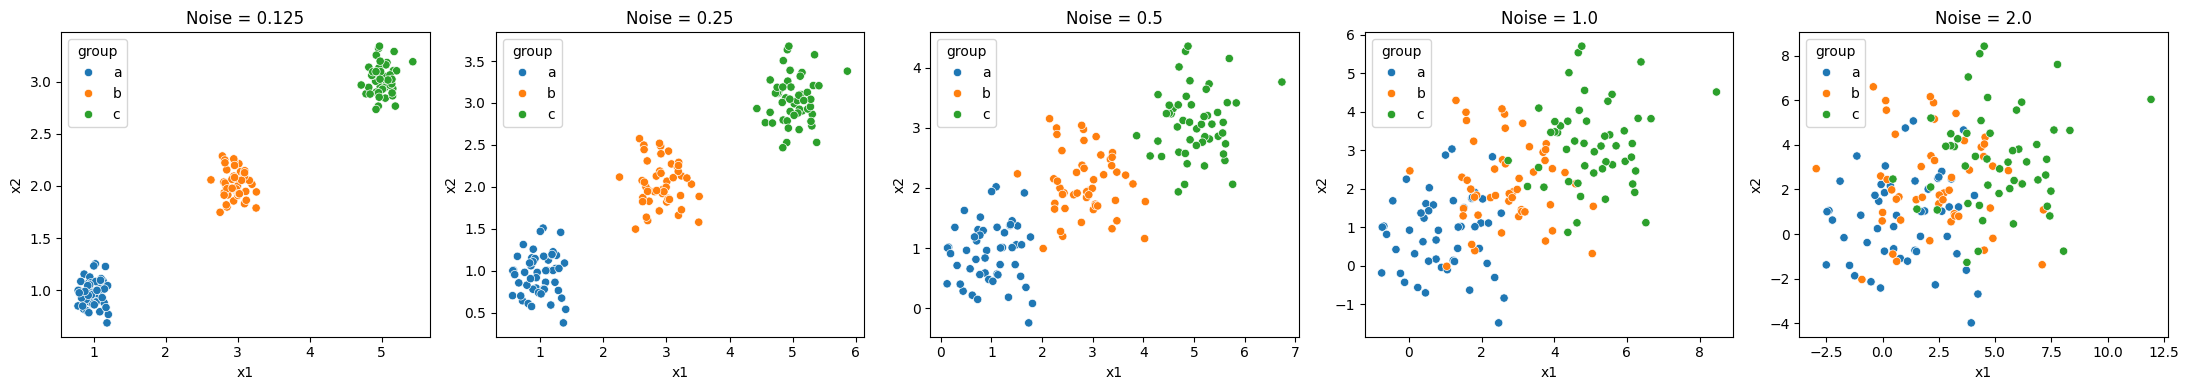

In [26]:
# Question 1.2 AI-Assisted Solution

# One scatterplot per noise level, colored by the true group
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (noise, df) in zip(axes, datasets.items()):
    sns.scatterplot(data=df, x="x1", y="x2", hue="group", ax=ax)
    ax.set(title=f"Noise = {noise}", xlabel="x1", ylabel="x2")

plt.tight_layout()
plt.show()

As the noise increases, the clusters become less visually distinct. At noise levels of 0.125 and 0.25, the three groups are tightly concentrated around their centers and easy to distinguish. At 0.5, the groups begin spreading out but remain fairly recognizable. At 1.0, there is considerable overlap, and at 2.0, the groups are so dispersed that identifying three distinct clusters becomes difficult. This shows that increasing noise makes it harder for k-means to separate the underlying groups accurately.

SSE by k and noise level:
noise   0.125   0.250   0.500   1.000    2.000
k                                             
1      511.61  533.25  606.62  873.69  1889.20
2      128.89  142.72  186.78  361.59  1071.81
3        4.91   19.65   77.82  254.91   792.27
4        4.33   17.33   67.19  212.65   591.18
5        3.80   15.24   58.74  175.47   501.88
6        3.23   13.04   50.45  147.00   418.35
7        2.79   11.49   42.96  123.19   353.84
8        2.42    9.72   36.96  106.02   303.45
9        2.06    8.35   32.81   94.74   264.42
10       1.91    7.47   29.65   82.95   245.99


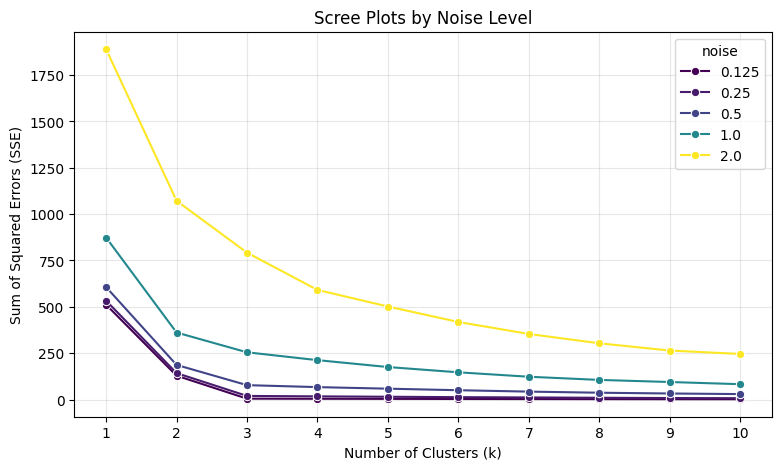

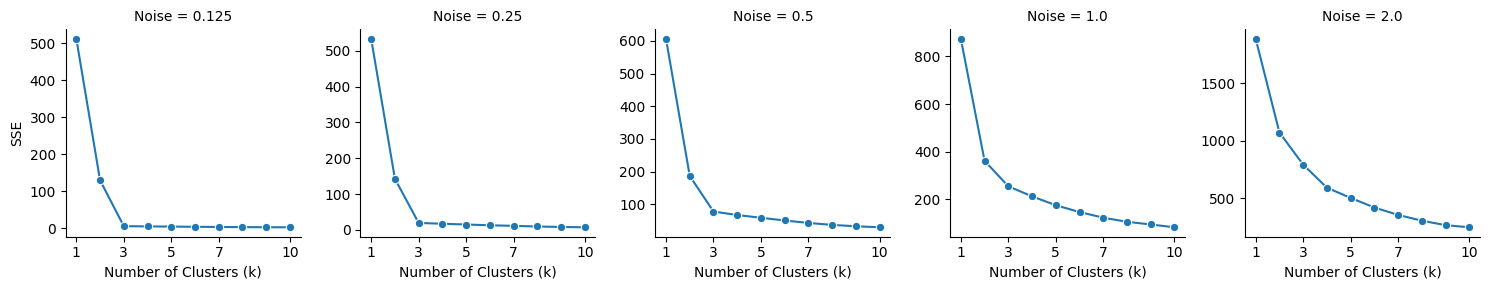

In [27]:
# Question 1.3 AI-Assisted Solution

# x1 and x2 are already on the same scale
ks = np.arange(1, 11)
rows = []

for noise, df in datasets.items():
    X = df[["x1", "x2"]]
    for k in ks:
        model = KMeans(n_clusters=k, max_iter=300,
                       n_init=10, random_state=0).fit(X)
        rows.append({"noise": noise, "k": k, "SSE": model.inertia_})

scree = pd.DataFrame(rows)

# SSE table
print("SSE by k and noise level:")
print(scree.pivot(index="k", columns="noise", values="SSE").round(2))

# All scree curves on one plot
plt.figure(figsize=(9, 5))
sns.lineplot(data=scree, x="k", y="SSE", hue="noise",
             marker="o", palette="viridis")
plt.title("Scree Plots by Noise Level")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.xticks(ks)
plt.grid(alpha=0.3)
plt.show()

# Separate plots to compare the shape of each elbow
g = sns.relplot(data=scree, x="k", y="SSE", col="noise",
                kind="line", marker="o",
                facet_kws={"sharey": False}, height=3)

g.set_axis_labels("Number of Clusters (k)", "SSE")
g.set_titles("Noise = {col_name}")
g.set(xticks=[1, 3, 5, 7, 10])
plt.show()

At low noise levels, the scree plots show a clear elbow at k = 3, which matches the three groups used to generate the data. At noise 0.125, SSE falls sharply from 128.89 at k = 2 to 4.91 at k = 3, but decreases only slightly after that. As noise increases, the elbow becomes less distinct because the groups overlap more and additional clusters continue reducing SSE. At noise 1.0 and 2.0, it becomes difficult to confidently identify the correct k. Comparing the plots also shows that the overall SSE increases substantially with noise, so looking at the shape of each curve is more useful than comparing their absolute values.

**Question 1.4 AI-Assisted Solution**

The elbow represents the point where adding more clusters stops producing substantial improvements in SSE. In this simulation, there are three true groups, so increasing k from 1 to 3 allows the algorithm to place a centroid near each group's center. At noise 0.125, SSE falls from 511.61 at k = 1 to 4.91 at k = 3. Increasing k beyond 3 mainly divides existing groups into smaller clusters rather than identifying meaningful new ones. This produces diminishing reductions in SSE and creates the elbow. When noise increases, the groups overlap more, so the distinction between meaningful clusters and random variation becomes less clear. As a result, the elbow becomes harder to identify, and selecting k requires more judgment.

In [28]:
# Question 2.1 AI-Assisted Solution

# Load the data
df = pd.read_csv("SIPRI Military Expenditure Database.csv")

print(f"{df.shape[0]} rows, {df.shape[1]} columns\n")
print("Column types:")
print(df.dtypes, "\n")

# Keep only 2020 and drop rows with missing values
mil = df.loc[df["Year"] == 2020].dropna().copy()

# Drop the leftover index column
mil = mil.drop(columns="index")

print(f"2020 rows after dropping missing values: {mil.shape[0]}")
print(f"Unique countries: {mil['Country'].nunique()}\n")

# Summary of the four numeric variables
num_vars = ["Spending (2020 USD)", "Spending per Capita",
            "Percent of Government Spending", "Percent of GDP"]

print("Numeric summary:")
print(mil[num_vars].describe().round(4), "\n")

# Largest spenders
print("Top 5 countries by total spending:")
print(mil.sort_values("Spending (2020 USD)", ascending=False)
         [["Country"] + num_vars].head().to_string(index=False))

5882 rows, 7 columns

Column types:
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

2020 rows after dropping missing values: 148
Unique countries: 148

Numeric summary:
       Spending (2020 USD)  Spending per Capita  \
count             148.0000             148.0000   
mean            13153.7477             268.2645   
std             68005.2361             430.4349   
min                 8.6225               0.5801   
25%               204.8772              20.5535   
50%               959.5354              81.5067   
75%              5289.9983             326.2678   
max            778397.2000            2520.3985   

       Percent of Government Spending  Percent of GDP  
count                        148.0000        148.0000

After filtering the dataset to 2020 and removing missing values, I have 148 countries, each appearing once. All four numeric variables are already stored as floats, so no additional type conversion is needed. I also removed the unnecessary index column. The spending variables have very different ranges, and total military expenditure is heavily skewed toward a few large countries. Therefore, min-max normalization is necessary before applying k-means so that variables with larger values do not dominate the clustering.

Scaled ranges:
     Spending (2020 USD)  Spending per Capita
min                  0.0                  0.0
max                  1.0                  1.0 

SSE by k:
 k   SSE
 1 5.411
 2 2.435
 3 1.322
 4 0.629
 5 0.415
 6 0.311
 7 0.212
 8 0.147
 9 0.104
10 0.086


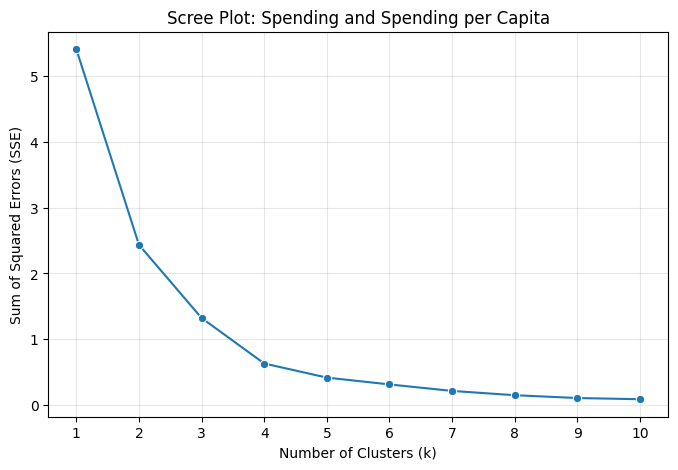

In [29]:
# Question 2.2 AI-Assisted Solution (scaling and scree plot)

# Max-min normalize the two spending variables
features_a = ["Spending (2020 USD)", "Spending per Capita"]
unscaled_a = mil.loc[:, features_a]

mins_a = unscaled_a.min()
ranges_a = unscaled_a.max() - mins_a
X_a = (unscaled_a - mins_a) / ranges_a

print("Scaled ranges:")
print(X_a.agg(["min", "max"]), "\n")

# Scree plot for k = 1 to 10
ks = np.arange(1, 11)

SSE_a = [
    KMeans(n_clusters=k, max_iter=300, n_init=10,
           random_state=0).fit(X_a).inertia_
    for k in ks
]

print("SSE by k:")
print(pd.DataFrame({"k": ks, "SSE": np.round(SSE_a, 3)}).to_string(index=False))

plt.figure(figsize=(8, 5))
sns.lineplot(x=ks, y=SSE_a, marker="o")
plt.title("Scree Plot: Spending and Spending per Capita")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.xticks(ks)
plt.grid(alpha=0.3)
plt.show()

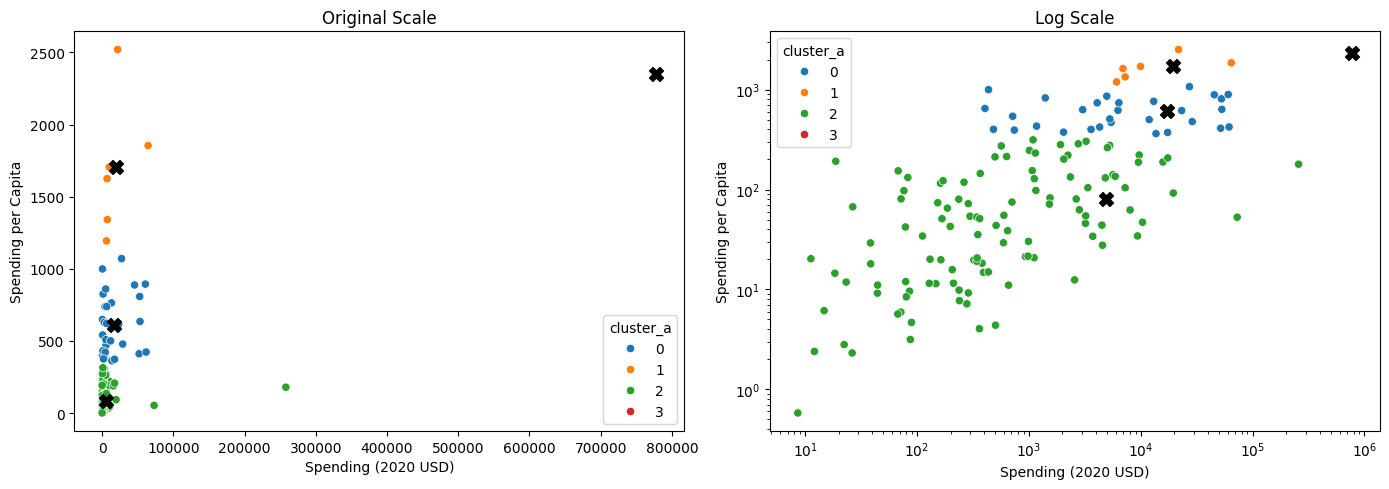

Describe table by cluster:
cluster_a                         0         1          2          3
Spending (2020 USD) count     30.00      6.00     111.00       1.00
                    mean   17077.59  19443.36    4859.19  778397.20
                    std    20583.05  22861.51   25405.74        NaN
                    min      405.79   6095.71       8.62  778397.20
                    25%     2294.04   7023.25     130.01  778397.20
                    50%     5857.06   8624.23     382.46  778397.20
                    75%    26296.00  18857.07    2297.03  778397.20
                    max    61712.54  64558.40  257973.43  778397.20
Spending per Capita count     30.00      6.00     111.00       1.00
                    mean     607.48   1706.72      80.06    2351.63
                    std      206.93    466.38      83.50        NaN
                    min      362.47   1193.60       0.58    2351.63
                    25%      422.21   1412.08      14.88    2351.63
                    5

In [30]:
# Question 2.2 AI-Assisted Solution (k-means with k = 4)

k_a = 4
model_a = KMeans(n_clusters=k_a, max_iter=300,
                 n_init=10, random_state=0).fit(X_a)

mil["cluster_a"] = model_a.labels_

# Convert cluster centers back to original units
centers_a = model_a.cluster_centers_ * ranges_a.to_numpy() + mins_a.to_numpy()

# Scatterplots on original and log scales
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, log in zip(axes, [False, True]):
    sns.scatterplot(data=mil, x="Spending (2020 USD)",
                    y="Spending per Capita", hue="cluster_a",
                    palette="tab10", ax=ax)

    ax.scatter(centers_a[:, 0], centers_a[:, 1],
               color="black", marker="X", s=100)

    if log:
        ax.set(xscale="log", yscale="log", title="Log Scale")
    else:
        ax.set(title="Original Scale")

plt.tight_layout()
plt.show()

# Describe table by cluster
print("Describe table by cluster:")
print(mil.groupby("cluster_a")[features_a].describe().round(2).T, "\n")

# Cluster sizes and U.S. membership
print("Cluster sizes:")
print(mil["cluster_a"].value_counts().sort_index(), "\n")

us_a = mil.loc[mil["Country"] == "United States of America",
               "cluster_a"].iloc[0]
print(f"United States is in cluster {us_a}\n")

# Countries in each cluster
for c in sorted(mil["cluster_a"].unique()):
    members = mil.loc[mil["cluster_a"] == c].sort_values(
        "Spending (2020 USD)", ascending=False)
    names = members["Country"].tolist()
    shown = ", ".join(names[:15]) + (
        f", ... (+{len(names) - 15} more)" if len(names) > 15 else "")
    print(f"Cluster {c} ({len(names)} countries): {shown}\n")

I chose k = 4 because the scree plot shows diminishing improvements after four clusters. SSE decreases substantially through k = 4, but the reductions become much smaller afterward. The United States forms its own cluster because its total military expenditure is significantly higher than that of other countries. The remaining clusters separate countries based on combinations of total spending and spending per capita, with wealthier countries generally spending more per person. The log-scale plot makes the differences among smaller countries easier to see. This also demonstrates how extreme outliers like the United States can influence k-means, since the algorithm tries to minimize squared distances. Although k = 3 could also be considered, k = 4 better captures the differences in spending in this dataset.

Scaled ranges:
     Percent of Government Spending  Percent of GDP
min                             0.0             0.0
max                             1.0             1.0 

SSE by k:
 k   SSE
 1 6.961
 2 2.927
 3 1.996
 4 1.477
 5 1.083
 6 0.803
 7 0.646
 8 0.535
 9 0.438
10 0.386


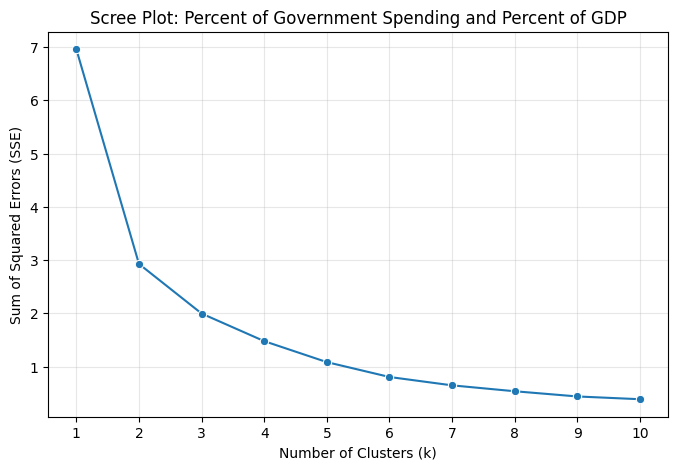

In [31]:
# Question 2.3 AI-Assisted Solution (scaling and scree plot)

# Max-min normalize the two percentage variables
features_b = ["Percent of Government Spending", "Percent of GDP"]
unscaled_b = mil.loc[:, features_b]

mins_b = unscaled_b.min()
ranges_b = unscaled_b.max() - mins_b
X_b = (unscaled_b - mins_b) / ranges_b

print("Scaled ranges:")
print(X_b.agg(["min", "max"]), "\n")

# Scree plot for k = 1 to 10
SSE_b = [
    KMeans(n_clusters=k, max_iter=300, n_init=10,
           random_state=0).fit(X_b).inertia_
    for k in ks
]

print("SSE by k:")
print(pd.DataFrame({"k": ks, "SSE": np.round(SSE_b, 3)}).to_string(index=False))

plt.figure(figsize=(8, 5))
sns.lineplot(x=ks, y=SSE_b, marker="o")
plt.title("Scree Plot: Percent of Government Spending and Percent of GDP")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.xticks(ks)
plt.grid(alpha=0.3)
plt.show()

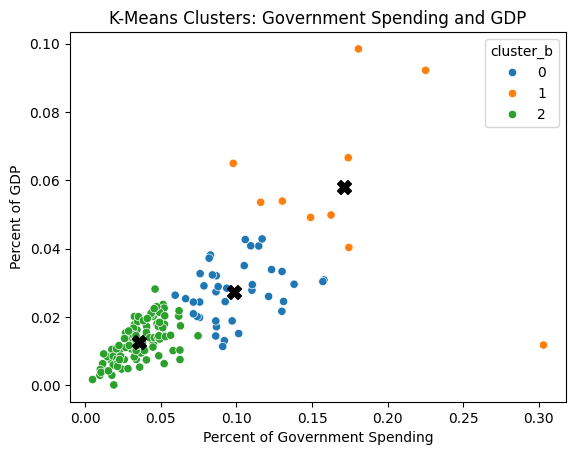

Describe table by cluster:
cluster_b                                   0        1        2
Percent of Government Spending count  39.0000  10.0000  99.0000
                               mean    0.0987   0.1713   0.0358
                               std     0.0241   0.0587   0.0145
                               min     0.0595   0.0979   0.0049
                               25%     0.0824   0.1350   0.0259
                               50%     0.0920   0.1682   0.0343
                               75%     0.1126   0.1791   0.0474
                               max     0.1579   0.3030   0.0746
Percent of GDP                 count  39.0000  10.0000  99.0000
                               mean    0.0274   0.0581   0.0127
                               std     0.0082   0.0249   0.0057
                               min     0.0113   0.0117   0.0001
                               25%     0.0213   0.0493   0.0084
                               50%     0.0278   0.0537   0.0132
             

In [32]:
# Question 2.3 AI-Assisted Solution (k-means with k = 3)

k_b = 3
model_b = KMeans(n_clusters=k_b, max_iter=300,
                 n_init=10, random_state=0).fit(X_b)

mil["cluster_b"] = model_b.labels_

# Convert cluster centers back to original units
centers_b = model_b.cluster_centers_ * ranges_b.to_numpy() + mins_b.to_numpy()

# Scatterplot with cluster centers
ax = sns.scatterplot(data=mil, x="Percent of Government Spending",
                     y="Percent of GDP", hue="cluster_b",
                     palette="tab10")

ax.scatter(centers_b[:, 0], centers_b[:, 1],
           color="black", marker="X", s=100)

ax.set(title="K-Means Clusters: Government Spending and GDP",
       xlabel="Percent of Government Spending",
       ylabel="Percent of GDP")
plt.show()

# Describe table by cluster
print("Describe table by cluster:")
print(mil.groupby("cluster_b")[features_b].describe().round(4).T, "\n")

# Cluster sizes and U.S. membership
print("Cluster sizes:")
print(mil["cluster_b"].value_counts().sort_index(), "\n")

us_b = mil.loc[mil["Country"] == "United States of America",
               "cluster_b"].iloc[0]
print(f"United States is in cluster {us_b}\n")

# Countries in each cluster
for c in sorted(mil["cluster_b"].unique()):
    members = mil.loc[mil["cluster_b"] == c].sort_values(
        "Percent of GDP", ascending=False)
    names = members["Country"].tolist()
    shown = ", ".join(names[:15]) + (
        f", ... (+{len(names) - 15} more)" if len(names) > 15 else "")
    print(f"Cluster {c} ({len(names)} countries): {shown}\n")

# Compare with Question 2.2
print("Q2.2 clusters (rows) vs. Q2.3 clusters (columns):")
print(pd.crosstab(mil["cluster_a"], mil["cluster_b"]))

The scree plot has a less distinct elbow than in Question 2.2, but I chose k = 3 because it provides a reasonable balance between reducing SSE and keeping the clusters interpretable. The clusters now represent differences in how much of a country's government budget and GDP are devoted to military spending, rather than the total amount spent. Countries with relatively small economies can therefore appear in higher-spending clusters if they devote a large share of their resources to the military. This differs from Question 2.2, where large and wealthy countries were more prominent. The U.S. is no longer isolated simply because of its total spending. Since the elbow is fairly soft, k = 2 could also be reasonable, but k = 3 provides a more detailed distinction between low, moderate, and high military spending burdens.

Scaled ranges:
     Spending (2020 USD)  Spending per Capita  Percent of Government Spending  \
min                  0.0                  0.0                             0.0   
max                  1.0                  1.0                             1.0   

     Percent of GDP  
min             0.0  
max             1.0   

SSE by k:
 k    SSE
 1 12.372
 2  7.710
 3  5.193
 4  4.207
 5  3.258
 6  2.686
 7  2.251
 8  1.889
 9  1.613
10  1.454


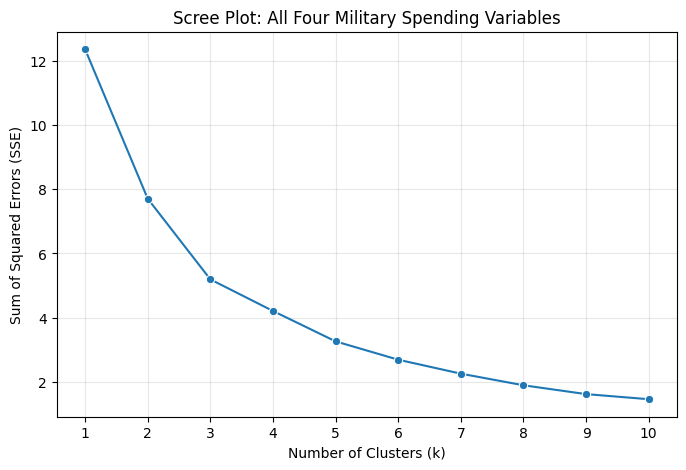

In [33]:
# Question 2.4 AI-Assisted Solution (scaling and scree plot)

# Max-min normalize all four numeric variables
features_c = ["Spending (2020 USD)", "Spending per Capita",
              "Percent of Government Spending", "Percent of GDP"]

unscaled_c = mil.loc[:, features_c]
mins_c = unscaled_c.min()
ranges_c = unscaled_c.max() - mins_c
X_c = (unscaled_c - mins_c) / ranges_c

print("Scaled ranges:")
print(X_c.agg(["min", "max"]), "\n")

# Scree plot for k = 1 to 10
SSE_c = [
    KMeans(n_clusters=k, max_iter=300, n_init=10,
           random_state=0).fit(X_c).inertia_
    for k in ks
]

print("SSE by k:")
print(pd.DataFrame({"k": ks, "SSE": np.round(SSE_c, 3)}).to_string(index=False))

plt.figure(figsize=(8, 5))
sns.lineplot(x=ks, y=SSE_c, marker="o")
plt.title("Scree Plot: All Four Military Spending Variables")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.xticks(ks)
plt.grid(alpha=0.3)
plt.show()

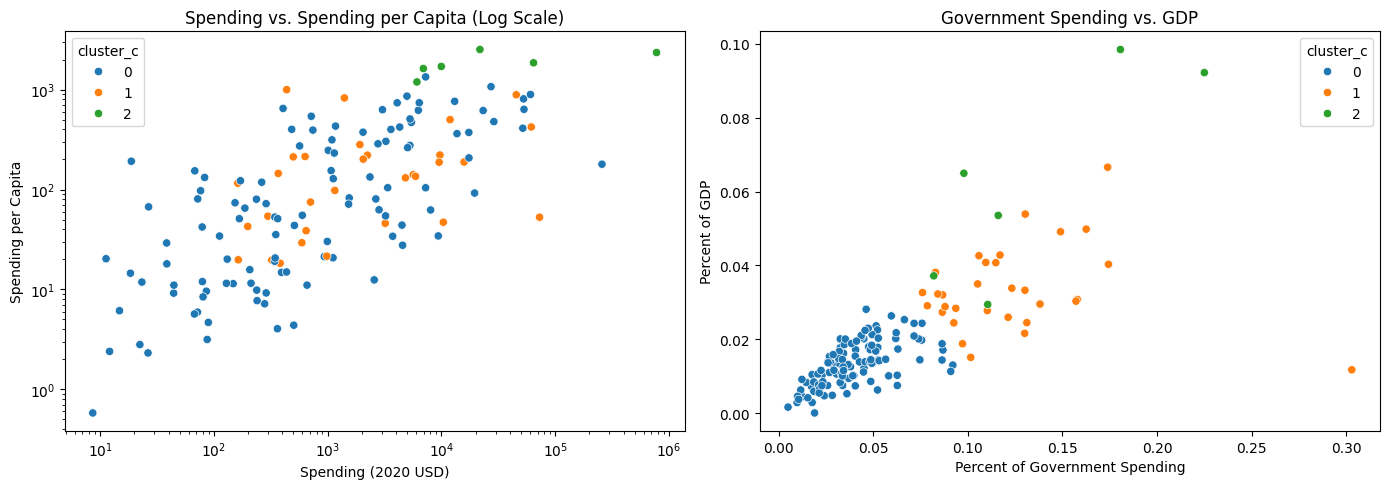

Describe table by cluster:
cluster_c                                       0           1            2
Spending (2020 USD)            count     111.0000     31.0000       6.0000
                               mean     7086.4728   8786.0866  147964.5820
                               std     26479.3799  17901.9091  309635.1896
                               min         8.6225    162.3734    6095.7087
                               25%       130.0102    467.7879    7700.4246
                               50%       567.6507   1404.7872   15897.5706
                               75%      3910.1075   7739.1662   53872.9424
                               max    257973.4298  72937.0640  778397.2000
Spending per Capita            count     111.0000     31.0000       6.0000
                               mean      196.9268    212.6891    1875.1508
                               std       267.7885    257.8420     489.8002
                               min         0.5801     18.2971    1193.598

In [34]:
# Question 2.4 AI-Assisted Solution (k-means with k = 3)

k_c = 3
model_c = KMeans(n_clusters=k_c, max_iter=300,
                 n_init=10, random_state=0).fit(X_c)

mil["cluster_c"] = model_c.labels_

# Plot clusters using both pairs of variables
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=mil, x="Spending (2020 USD)",
                y="Spending per Capita", hue="cluster_c",
                palette="tab10", ax=axes[0])

axes[0].set(xscale="log", yscale="log",
            title="Spending vs. Spending per Capita (Log Scale)")

sns.scatterplot(data=mil, x="Percent of Government Spending",
                y="Percent of GDP", hue="cluster_c",
                palette="tab10", ax=axes[1])

axes[1].set(title="Government Spending vs. GDP")

plt.tight_layout()
plt.show()

# Describe table by cluster
print("Describe table by cluster:")
print(mil.groupby("cluster_c")[features_c].describe().round(4).T, "\n")

# Compare cluster means
print("Cluster means:")
print(mil.groupby("cluster_c")[features_c].mean().round(4), "\n")

# Cluster sizes and U.S. membership
print("Cluster sizes:")
print(mil["cluster_c"].value_counts().sort_index(), "\n")

us_c = mil.loc[mil["Country"] == "United States of America",
               "cluster_c"].iloc[0]
print(f"United States is in cluster {us_c}\n")

# Countries in each cluster
for c in sorted(mil["cluster_c"].unique()):
    members = mil.loc[mil["cluster_c"] == c].sort_values(
        "Spending (2020 USD)", ascending=False)
    names = members["Country"].tolist()
    shown = ", ".join(names[:15]) + (
        f", ... (+{len(names) - 15} more)" if len(names) > 15 else "")
    print(f"Cluster {c} ({len(names)} countries): {shown}\n")

# Compare with Questions 2.2 and 2.3
print("Q2.2 clusters (rows) vs. Q2.4 clusters (columns):")
print(pd.crosstab(mil["cluster_a"], mil["cluster_c"]), "\n")

print("Q2.3 clusters (rows) vs. Q2.4 clusters (columns):")
print(pd.crosstab(mil["cluster_b"], mil["cluster_c"]))

Using all four variables, I chose k = 3 because the scree plot shows diminishing improvements after three clusters, although the elbow is not especially sharp. The results combine the patterns from the previous two questions by considering both the total amount countries spend and the share of their resources devoted to military expenditures. A small group of countries, including Saudi Arabia, Israel, Kuwait, and Oman, stands out for having relatively high spending across several measures. The United States remains unusual because of its extremely large total expenditure, but it is not necessarily grouped with countries that have the highest military spending burdens. Comparing the cluster memberships shows that countries with similar total spending do not always devote similar proportions of their economies to the military. A nearby value such as k = 4 could provide additional detail, but k = 3 offers a simpler interpretation.

**Question 2.5 AI-Assisted Solution**

Yes, k-means identified several useful patterns in military spending, although the results depend heavily on which variables are included. In Question 2.2, the clusters primarily reflected differences in total expenditure and spending per capita, with the United States standing out as a major outlier. In Question 2.3, the clusters instead highlighted differences in military spending relative to government budgets and GDP. Question 2.4 combined these perspectives and showed that spending large amounts does not necessarily mean a country devotes a large share of its resources to the military. For example, China has very high total military expenditure but a relatively lower spending burden, while countries such as Saudi Arabia and Israel devote larger shares of their resources to defense. The analysis also has limitations. Outliers can strongly influence k-means, and the scree plots do not always provide a clear choice of k. Overall, clustering is useful for identifying groups of countries with similar spending patterns, but it cannot explain the political or economic reasons behind those differences.

### *Reflection on AI assistance
In your own words without generative AI.

The AI was helpful for going back through my original work and pointing out a few areas where I could make my analysis clearer. One of the most useful suggestions was improving how I presented the scree plots. Making the plots more consistent helped me better understand how increasing noise makes it harder to identify the correct number of clusters. The AI also suggested expanding my interpretation of the military expenditure data. I thought this was helpful because I could see how much the results changed depending on which variables I included, especially with countries like the United States that have extremely high total military spending. Another useful suggestion was explaining alternative values of k when the elbow was not completely clear. I did not think it was necessary to do a full sensitivity analysis, since that would go beyond what the assignment was asking for, but I did think it was worth acknowledging that more than one value of k could be reasonable. Overall, the AI was most helpful for improving my explanations and making my original analysis more complete without significantly changing my approach.